# Исследование коллекции Еврейского музея и центра толерантности

Основные этапы:

1. Создается абстрактный класс ArtifactBase, по его подобию создаются классы Judaica, Graphics, Paintings и т.д.
2. С сайта ЕМЦТ парсятся все их артефакты (+метаданные) и записываются как оббъекты соответствующих классов.
+В коде есть функция добавления артефактов в коллекцию (создания нового артефакта).
+Переопределены __add__, __str__ и __repr__
3. Реализована функция поиска по ключевым словам (п о любмы полям метаданных)
4. Реализована сортировка по разделам (по классам).
5. Построены визуализации, характеризующие коллекцию:
  + Распределение по типам
  + Распределение по годам создания
  + Распределение по типам-техникам-материалам (sunburst)


# Подготовка: создание классов

Создадим абстрактный класс "ArtifactBase", по его подобию создадим классы "Judaica", "Arts_and_crafts" и т.д., соответствующие типам артефактов (фильтрам на сайте).

У классов будут методы display_details (показать метаданные) и display_description (показать краткое описание)

In [42]:
from abc import ABC, abstractmethod

class ArtifactBase(ABC):
    def __init__(self, name, description):
        self.name = name
        self._description = description

    @abstractmethod
    def display_details(self):
        pass

class CommonArtifact(ArtifactBase):
    def __init__(self, name, description, artist=None, place=None, date=None,
                 period=None, material=None, technique=None, theme=None):
        super().__init__(name, description)
        self.artist = artist
        self.place = place
        self.date = date
        self.period = period
        self.material = material
        self.technique = technique
        self.theme = theme

    def display_details(self):
        details = [
            f"Произведение искусства: {self.name}",
            f"Автор: {self.artist or 'не указан'}",
            f"Место происхождения: {self.place or 'не указано'}",
            f"Дата: {self.date or 'не указана'}",
            f"Период: {self.period or 'не указан'}",
            f"Материал: {self.material or 'не указан'}",
            f"Техника: {self.technique or 'не указана'}",
            f"Тема: {self.theme or 'не указана'}"
        ]
        return "\n".join(details)

    def __str__(self):
        return self.display_details()

    def __repr__(self):
        return f"CommonArtifact('{self.name}')"

class Judaica(CommonArtifact):
    pass

class Arts_and_crafts(CommonArtifact):
    pass

class Household_items(CommonArtifact):
    pass

class Painting(CommonArtifact):
    pass

class Graphics(CommonArtifact):
    pass

class Documents_and_photos(CommonArtifact):
    pass

class Prints(CommonArtifact):
    pass

# Исключения и проверки

Сосздадим исключение для неизвестного типа (в нашем случае -- для несуществующего класса) при создании нового артефакта.

In [43]:
class InvalidArtifactTypeError(Exception):
    """Исключение возникает, когда пользователь при создании артефакта передает неизвестный тип"""
    pass

In [44]:
import datetime

last_user_role = None
last_input_time = None

def ask_role():
    global last_user_role, last_input_time

    current_time = datetime.datetime.now()

    if last_user_role and (current_time - last_input_time).total_seconds() <= 60: #если ввели роль меньше минуты назад (для долгих по выполнению функций)
        return last_user_role

    last_user_role = input('Введите вашу роль: ')
    last_input_time = current_time
    return last_user_role

In [45]:
#функция проверки роли для осуществления какого-то действия
def check_permissions(required_role='admin'):
    def decorator(func):
        def wrapper(*args, **kwargs):
            user_role = kwargs.pop('role', None)

            if user_role != required_role:
                raise PermissionError(
                    f"Недостаточно прав. Требуется роль '{required_role}', ваша роль: {user_role or 'не указана'}."
                )

            return func(*args, **kwargs)

        return wrapper
    return decorator

In [46]:
class EditArtifact:

    @staticmethod
    @check_permissions(required_role='admin')
    def create_artifact(type_, **kwargs):
        role = kwargs.pop('role', None)
        if type_.lower() == 'иудаика':
            return Judaica(**kwargs)
        elif type_.lower() == 'декоративно-прикладное искусство':
            return Arts_and_crafts(**kwargs)
        elif type_.lower() == 'предметы быта':
            return Household_items(**kwargs)
        elif type_.lower() == 'живопись':
            return Painting(**kwargs)
        elif type_.lower() == 'графика':
            return Graphics(**kwargs)
        elif type_.lower() == 'документы и фотографии':
            return Documents_and_photos(**kwargs)
        elif type_.lower() == 'печатные материалы':
            return Prints(**kwargs)
        else:
            raise InvalidArtifactTypeError(f"Неизвестный тип артефакта '{type_}'") #вот тут используем искл.собст.типа

# Функция для парсинга сайта

В этом разделе кода я достаю экспонаты с сайта Еврейского музея и центра толерантности с поомщью библиотек requests и BeautifulSoup (еще используем re, потому что в одном месте понадобятся регулярные выражения).


In [47]:
import requests
from bs4 import BeautifulSoup
import re

class JewishMuseumCollectionScraper:

  def __init__(self, url):
    self.collection_pages = []
    self.all_links = []
    self.all_info = []
    self.meta_data = []
    self.all_results = []
    self.url = url
    self.headers = {"User-Agent": "Mozilla/5.0 (Macintosh; Intel Mac OS X 10_15_7) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/128.0.0.0 YaBrowser/24.10.0.0 Safari/537.36"}

  def get_last_page(self):
      resp = requests.get(self.url, headers=self.headers)

      if resp.status_code == 200:
        soup = BeautifulSoup(resp.content, 'html.parser')
        pagination_buttons = soup.select('.pagination__btn')

        if not pagination_buttons:
          return 1 #всего одна страина, если вообще нет элемента, чтобы переключать страницы
        last_button_href = pagination_buttons[-1].get('href')
        match = re.search(r'=(\d+)$', last_button_href)

        if match:
          return int(match.group(1))
        else:
          return 1 #считаем, что страница одна, если не получилось вытянуть регулярными выражениями

      else:
        print(f"Ошибка загрузки страницы. Status code: {resp.status_code}")
        return None


  def get_collection_pages(self):
    last_page = self.get_last_page()
    if last_page is None:
            return

    for i in range(1, last_page + 1):
      self.collection_pages.append(f"{self.url}/?PAGEN_1={i}")

    return self.collection_pages


  def get_all_links(self):
    for page in self.get_collection_pages():
      resp = requests.get(page, headers=self.headers)

      if resp.status_code == 200:
          soup = BeautifulSoup(resp.content, 'html.parser')
          items = soup.find_all('li', class_='museum-collection__item')

          for item in items:
            link = item.find('a')
            if link:
              href = link.get('href')
              full_url = f"https://www.jewish-museum.ru{href}"
              self.all_links.append(full_url)
      else:
        print(f"Ошибка загрузки страницы. Status code: {resp.status_code}")
        return None

    return self.all_links


  def get_all_results(self):
    for item in self.get_all_links():
        resp = requests.get(item, headers=self.headers)
        if resp.status_code == 200:
            soup = BeautifulSoup(resp.content, 'html.parser')

            title = soup.find('h1')
            title_text = title.get_text(strip=True) if title else None

            breadcrumbs = soup.find_all('a', class_='product__breadcrumbs-link')[1:]  # берем последнее значение в поле (потому что перед этим ссылка на "всю коллекцию")
            breadcrumbs_text = breadcrumbs[-1].get_text(strip=True) if breadcrumbs else None

            description = soup.find('div', class_='product__description')
            description_p = description.find('p').get_text(strip=True) if description else None

            titles = []
            means = []
            meta = soup.find_all('li', class_='product__property')
            for m in meta:
                span_text = m.span.get_text().strip()
                text_outside_span = m.get_text('', strip=True).replace(span_text, '')
                titles.append(span_text)
                means.append(text_outside_span)

            result_dict = {
                'title': title_text,
                'breadcrumbs': breadcrumbs_text,
                'description': description_p
            }
            result_dict.update(dict(zip(titles, means)))

            self.all_results.append(result_dict)
        else:
            print(f"Ошибка загрузки страницы. Status code: {resp.status_code}")

    return self.all_results


# Сам процесс загрузки артефактов с сайта



In [48]:
scraper = JewishMuseumCollectionScraper("https://www.jewish-museum.ru/collection")


In [ ]:
import json, os

CACHE = "artifacts.json"
if os.path.exists(CACHE):
    with open(CACHE, encoding="utf-8") as f:
        dic = json.load(f)
    print(f"Загружено из кэша: {len(dic)} записей")
else:
    dic = scraper.get_all_results()
    with open(CACHE, "w", encoding="utf-8") as f:
        json.dump(dic, f, ensure_ascii=False, indent=2)
    print(f"Распарсено и сохранено: {len(dic)} записей")

Загружено из кэша: 224 записей


In [50]:
artifacts = []
for item in dic:
    type_ = item['breadcrumbs'].split(', ')[0] #выделяем тип, чтобы потом передать в нужный класс при создании артефакта

    args_dict = {
    'name': item['title'],
    'description': item.get('description'),
    'artist': item.get('Автор:'),
    'place': item.get('Место происхождения:'),
    'date': item.get('Дата:'),
    'material': item.get('Материал:'),
    'technique': item.get('Техника:'),
    'theme': item.get('Темы:'),
    'period': item.get('Период:')
    }

    artifact = EditArtifact.create_artifact(type_, **args_dict, role = ask_role())
    artifacts.append(artifact)

## Всякие приколюшки

In [51]:
def find_artifacts_by_keyword(artifacts, keyword, fields=None):
    if fields is None:
        fields = ['name', '_description', 'theme']

    keyword_lower = keyword.lower()
    results = []

    for artifact in artifacts:
        text_to_search = ' '.join(
            str(getattr(artifact, field) or '')
            for field in fields
        )

        if keyword_lower in text_to_search.lower():
            results.append(artifact)

    for artifact in results:
      print(artifact.display_details())
      print('\n')

In [52]:
find_artifacts_by_keyword(
    artifacts,
    "акварель",
    fields=['name', 'material']
)

In [53]:
class FilterArtifacts:

  def __init__(self, types=None):
    self.types = set(types) if types else set()

  @classmethod
  def select(cls, artifact, types):
    return [item for item in artifacts if isinstance(item, types)]

  def __add__(self, other):
    if isinstance(other, type) and issubclass(other, ArtifactBase):
       return (self, other)
    elif isinstance(other, tuple):
       return self + other[0] + other[1:]


In [54]:
judaica_and_graphics = FilterArtifacts.select(artifacts, (Judaica, Graphics))
print(len(judaica_and_graphics))

123


## Визуализации

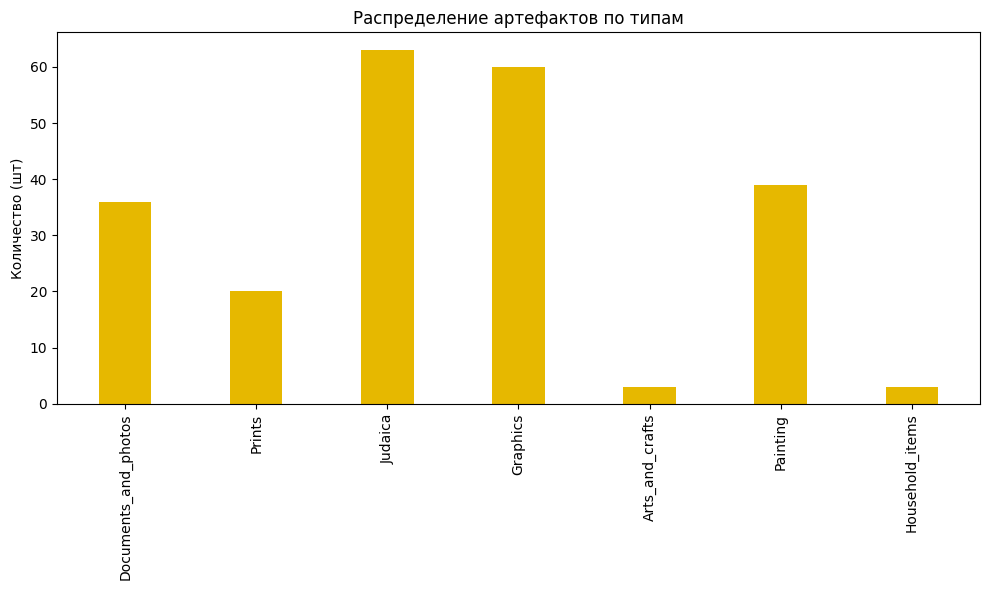

In [55]:
#распределение по типам

import matplotlib.pyplot as plt
from collections import Counter

types = Counter(type(a).__name__ for a in artifacts)

plt.figure(figsize=(10, 6))
plt.bar(types.keys(), types.values(), color = "#E6B800", width=0.4)
plt.title("Распределение артефактов по типам")
plt.xticks(rotation=90)
plt.ylabel("Количество (шт)")
plt.tight_layout()
plt.show()

Text(0.5, 1.0, 'Распределение артефактов по годам создания')

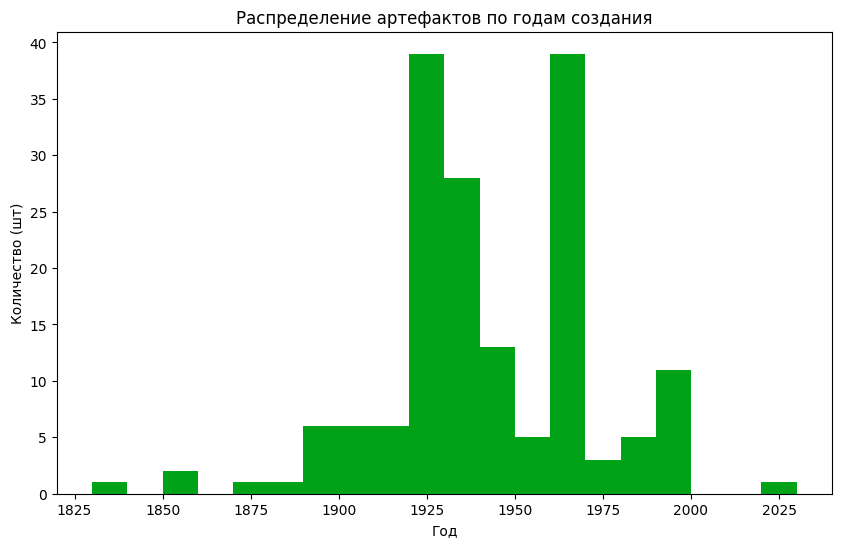

In [56]:
#распределение по годам
years = [int(m.group()) for a in artifacts
         if a.date and (m := re.search(r'\b(1[8-9]\d{2}|20\d{2})\b', a.date))]
plt.figure(figsize=(10, 6))
plt.hist(years, bins=range(min(years), max(years)+10, 10), color = "#00A318")
plt.xlabel("Год")
plt.ylabel("Количество (шт)")
plt.title("Распределение артефактов по годам создания")

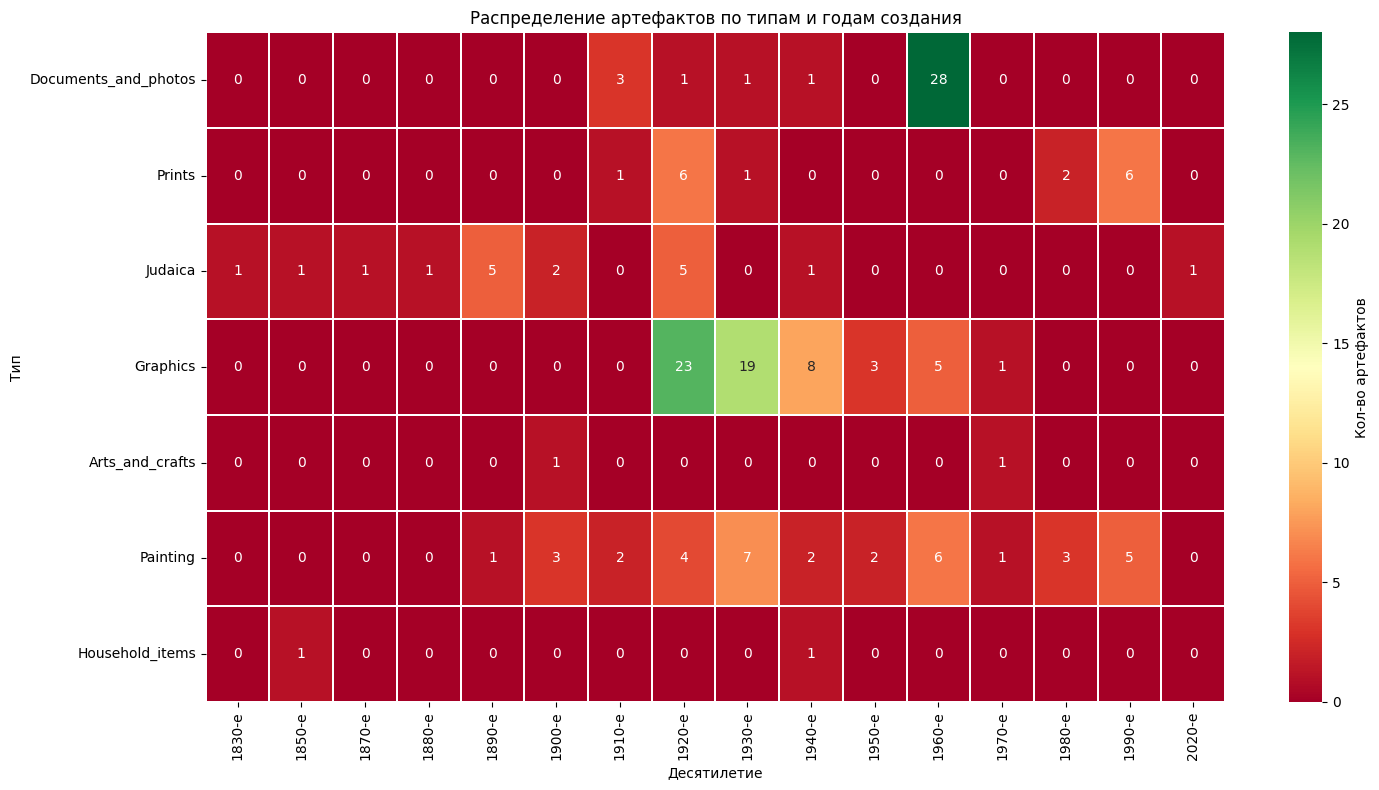

In [57]:
#распределение по годам и типам (тут надо упомянуть, что сумма по клетка будет меньше 224, потому что не у всех элементов указан год)
import numpy as np
import seaborn as sns

def plot_heatmap_years_types(artifacts, decade=True, cmap="YlOrRd", figsize=(16, 6), annot=True):
    rows = []
    for a in artifacts:
        if not a.date:
            continue
        m = re.search(r'\b(1[5-9]\d{2}|20\d{2})\b', a.date)
        if not m:
            continue
        year = int(m.group())
        if decade:
            year = (year // 10) * 10
        rows.append((type(a).__name__, year))

    years = sorted({y for _, y in rows})

    matrix = np.zeros((len(types), len(years)), dtype=int)
    t_index = {t: i for i, t in enumerate(types)}
    y_index = {y: j for j, y in enumerate(years)}

    for t, y in rows:
        matrix[t_index[t], y_index[y]] += 1

    plt.figure(figsize=(15, 8))
    sns.heatmap(matrix, xticklabels=[f"{y}-е" if decade else str(y) for y in years], yticklabels=types, cmap=cmap, annot=annot, fmt="d", linewidths=0.3, linecolor="white", cbar_kws={"label": "Кол-во артефактов"})
    plt.xlabel("Десятилетие" if decade else "Год")
    plt.ylabel("Тип")
    plt.title("Распределение артефактов по типам и годам создания")
    plt.xticks(rotation=90)
    plt.yticks(rotation=0)
    plt.tight_layout()
    plt.show()

plot_heatmap_years_types(artifacts, decade=True, cmap="RdYlGn")

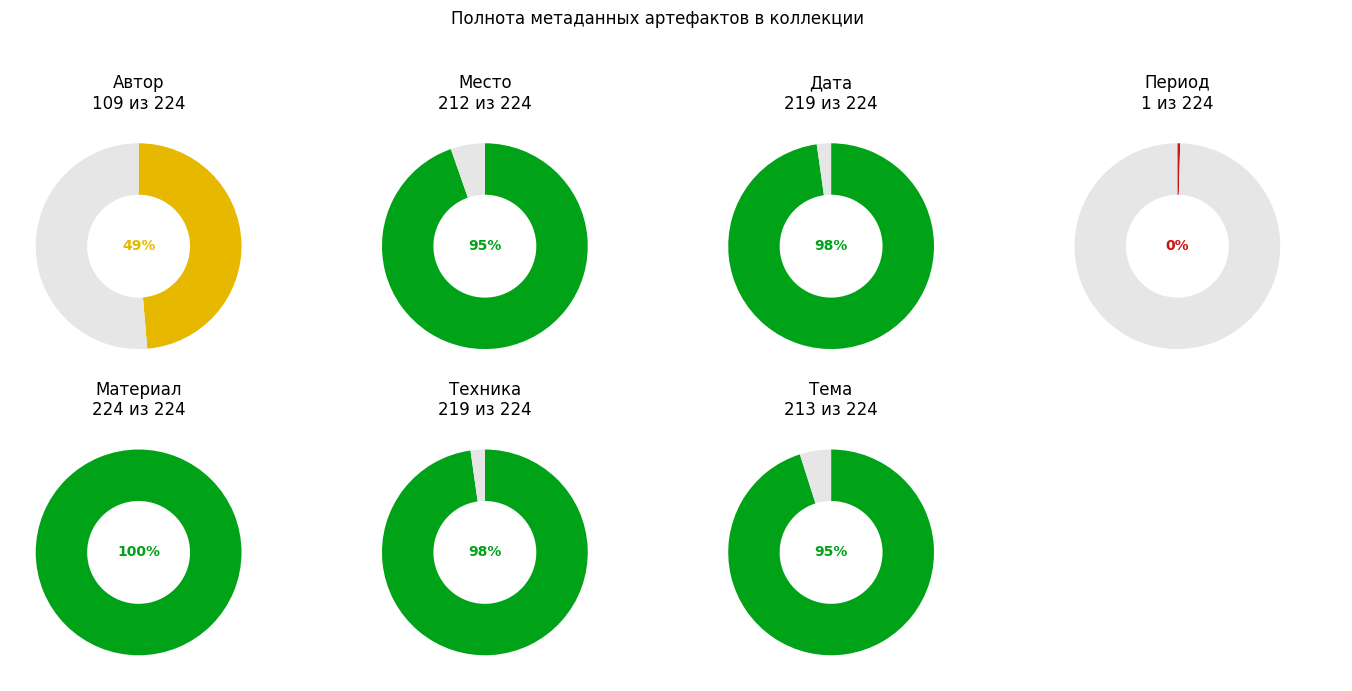

In [58]:
#оценка заполненности данных

fields = {'artist': 'Автор', 'place': 'Место', 'date': 'Дата', 'period': 'Период',
          'material': 'Материал', 'technique': 'Техника', 'theme': 'Тема'}
total = len(artifacts)

fig, axes = plt.subplots(2, 4, figsize=(14, 7))
for ax, (f, name) in zip(axes.flatten(), fields.items()):
    filled = sum(1 for a in artifacts if getattr(a, f))
    pct = filled / total * 100 if total else 0

    color = "#00A318" if pct >= 70 else ("#E6B800" if pct >= 30 else "#CE1313")

    ax.pie([filled, total - filled], colors=[color, "#E6E6E6"], startangle=90, counterclock=False, wedgeprops=dict(width=0.5))
    ax.text(0, 0, f"{pct:.0f}%", ha="center", va="center", fontweight="bold", color=color)
    ax.set_title(f"{name}\n{filled} из {total}")

axes.flatten()[-1].axis("off")
fig.suptitle("Полнота метаданных артефактов в коллекции")
fig.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

In [59]:
import plotly.express as px
import pandas as pd
df = pd.DataFrame([{'type': type(a).__name__, 'material': a.material or '—',
                    'technique': a.technique or '—'} for a in artifacts])
fig = px.sunburst(df, path=['type', 'material', 'technique'])
fig.update_layout(title="Иерархия коллекции: тип → материал → техника")


fig.show()